# 01 – Exploratory data analysis

Short look at the two targets (Zurich demand, Swiss day-ahead price), the time handling and the data quality,
before any model. Reads only the processed tables in `data/processed/` (built by `python -m src.pipeline --data --features`).
Saves six figures as `reports/figures/eda_*.png`; the report uses some of them.

Run from the repo root or from `notebooks/` – the first cell finds the project folder.

In [1]:
import os
from pathlib import Path
root = Path.cwd()
while not (root / 'config.yaml').exists():
    root = root.parent
os.chdir(root)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

FIG = Path('reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e1'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 130, 'font.size': 10, 'axes.edgecolor': INK2,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left', 'axes.titlesize': 11,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'legend.frameon': False})
pd.set_option('display.precision', 2)

h = pd.read_parquet('data/processed/hourly_actuals.parquet')   # one row per UTC hour, local delivery day
h['date'] = pd.to_datetime(h.delivery_date)
h = h[(h.date >= '2019-01-01') & (h.date <= '2026-10-31')].copy()
cal = pd.read_parquet('data/processed/calendar_features_daily.parquet')[['date', 'is_weekend', 'is_holiday', 'weekday']]
cal['date'] = pd.to_datetime(cal.date)
obs = pd.read_parquet('data/processed/weather_observed_hourly.parquet', columns=['timestamp_utc', 'temp_c', 'radiation_wm2'])
print(len(h), 'hours,', h.date.min().date(), '→', h.date.max().date())

68664 hours, 2019-01-01 → 2026-10-31


## 1. Demand: levels, daily and weekly pattern, temperature

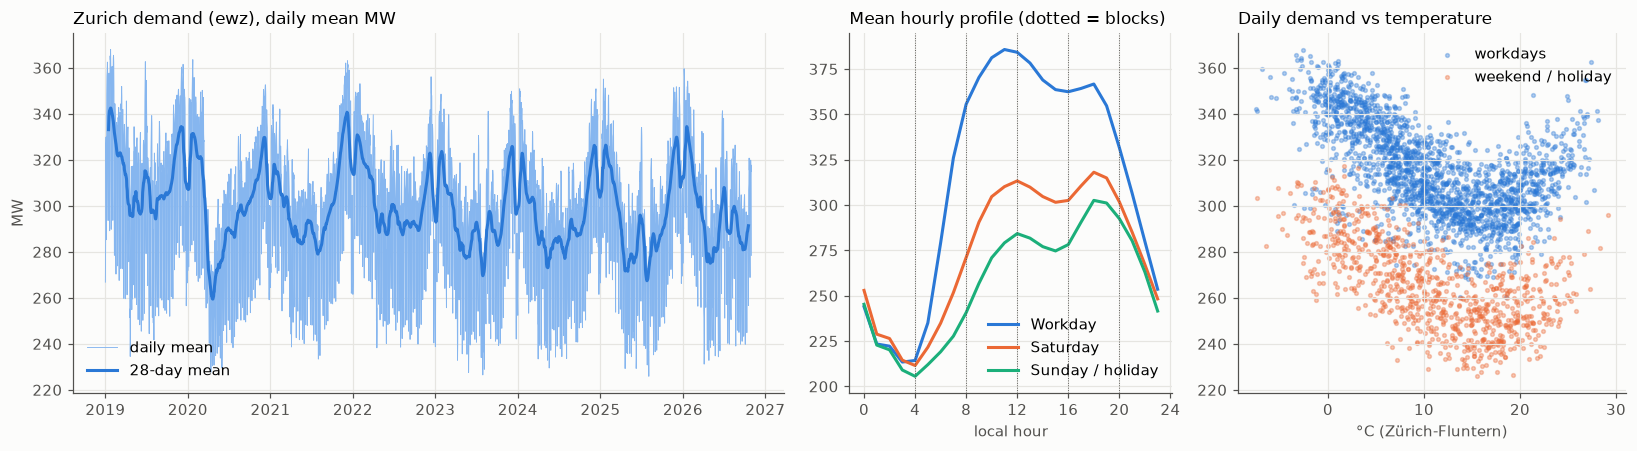

year
2019    312.9
2020    299.4
2021    301.1
2022    302.2
2023    295.1
2024    295.3
2025    295.9
2026    296.3


In [2]:
day = h.groupby('date').agg(demand=('demand_mw', 'mean'), price=('price_eur_mwh', 'mean')).reset_index()
day = day.merge(cal, on='date', how='left')
tday = obs.assign(date=pd.to_datetime(obs.timestamp_utc.dt.tz_convert('Europe/Zurich').dt.date)).groupby('date').temp_c.mean()
day = day.merge(tday.rename('temp_c'), left_on='date', right_index=True, how='left')
day['type'] = np.where(day.is_holiday == 1, 'Sunday / holiday',
               np.where(day.weekday == 6, 'Sunday / holiday', np.where(day.weekday == 5, 'Saturday', 'Workday')))
h2 = h.merge(day[['date', 'type']], on='date')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2.2, 1, 1.2]})
ax[0].plot(day.date, day.demand, color='#86b6ef', lw=0.6, label='daily mean')
ax[0].plot(day.date, day.demand.rolling(28, center=True).mean(), color=BLUE, lw=2, label='28-day mean')
ax[0].set_title('Zurich demand (ewz), daily mean MW'); ax[0].set_ylabel('MW'); ax[0].legend(loc='lower left')
for t, col in [('Workday', BLUE), ('Saturday', ORANGE), ('Sunday / holiday', AQUA)]:
    prof = h2[h2.type == t].groupby('hour_local').demand_mw.mean()
    ax[1].plot(prof.index, prof.values, color=col, lw=2, label=t)
for b in range(4, 24, 4): ax[1].axvline(b, color=INK2, lw=0.6, ls=':')
ax[1].set_xticks(range(0, 25, 4)); ax[1].set_title('Mean hourly profile (dotted = blocks)')
ax[1].set_xlabel('local hour'); ax[1].legend()
w = day[day.type == 'Workday']
ax[2].scatter(w.temp_c, w.demand, s=6, color=BLUE, alpha=0.35, label='workdays')
ax[2].scatter(day[day.type != 'Workday'].temp_c, day[day.type != 'Workday'].demand, s=6, color=ORANGE, alpha=0.35, label='weekend / holiday')
ax[2].set_title('Daily demand vs temperature'); ax[2].set_xlabel('°C (Zürich-Fluntern)'); ax[2].legend()
fig.tight_layout(); fig.savefig(FIG / 'eda_demand_overview.png'); plt.show()
print(day.assign(year=day.date.dt.year).groupby('year').demand.mean().round(1).to_string())

Demand repeats by hour of day and by day of the week. Workdays are about a quarter higher than Sundays at
midday. Demand rises on cold days (heating) and is fairly flat in mild weather; there is no strong summer
cooling peak. The level is almost constant over the years (2019 is a little higher).

## 2. Daylight-saving days: is the time handling right?

ewz labels its 15-minute values in local time, with the **end** of the interval. On the autumn clock change the
labels 02:00–02:45 appear twice; the loader converts to UTC and matches each pair with the ewz Netzebenen file
(UTC) instead of trusting the file order. Check: every local day must have 24 hours, except the spring day (23)
and the autumn day (25), and the extra hour must look like a normal night hour.

hours per local day: {24: 2845, 23: 8, 25: 8}
23-hour days: ['2019-03-31', '2020-03-29', '2021-03-28', '2022-03-27', '2023-03-26', '2024-03-31', '2025-03-30', '2026-03-29']
25-hour days: ['2019-10-27', '2020-10-25', '2021-10-31', '2022-10-30', '2023-10-29', '2024-10-27', '2025-10-26', '2026-10-25']


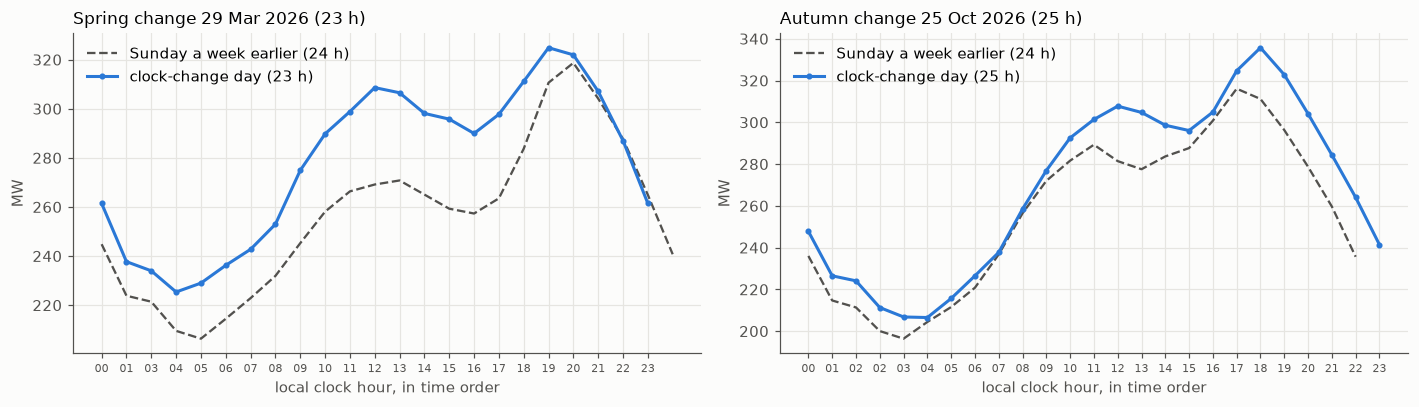

In [3]:
n = h.groupby('date').size()
print('hours per local day:', n.value_counts().to_dict())
print('23-hour days:', [d.date().isoformat() for d in n[n == 23].index])
print('25-hour days:', [d.date().isoformat() for d in n[n == 25].index])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, d_dst, d_ref, title in [(ax[0], '2026-03-29', '2026-03-22', 'Spring change 29 Mar 2026 (23 h)'),
                               (ax[1], '2026-10-25', '2026-10-18', 'Autumn change 25 Oct 2026 (25 h)')]:
    x = h[h.date == d_dst]; r = h[h.date == d_ref]
    a.plot(range(len(r)), r.demand_mw.values, color=INK2, lw=1.5, ls='--', label=f'Sunday a week earlier ({len(r)} h)')
    a.plot(range(len(x)), x.demand_mw.values, color=BLUE, lw=2, marker='o', ms=3, label=f'clock-change day ({len(x)} h)')
    a.set_xticks(range(len(x))); a.set_xticklabels(x.local_time.dt.strftime('%H'), fontsize=7)
    a.set_title(title); a.set_ylabel('MW'); a.set_xlabel('local clock hour, in time order'); a.legend()
fig.tight_layout(); fig.savefig(FIG / 'eda_dst_check.png'); plt.show()

Every year has exactly one 23-hour and one 25-hour day, and on the autumn day the repeated 02 hour sits smoothly
in the night valley (no jump, no doubled value). Blocks follow the local clock, so block 00–04 has 3 hours in
spring and 5 hours in autumn; the models therefore predict mean MW per block, not MWh.

## 3. Price: history, crisis and negative prices

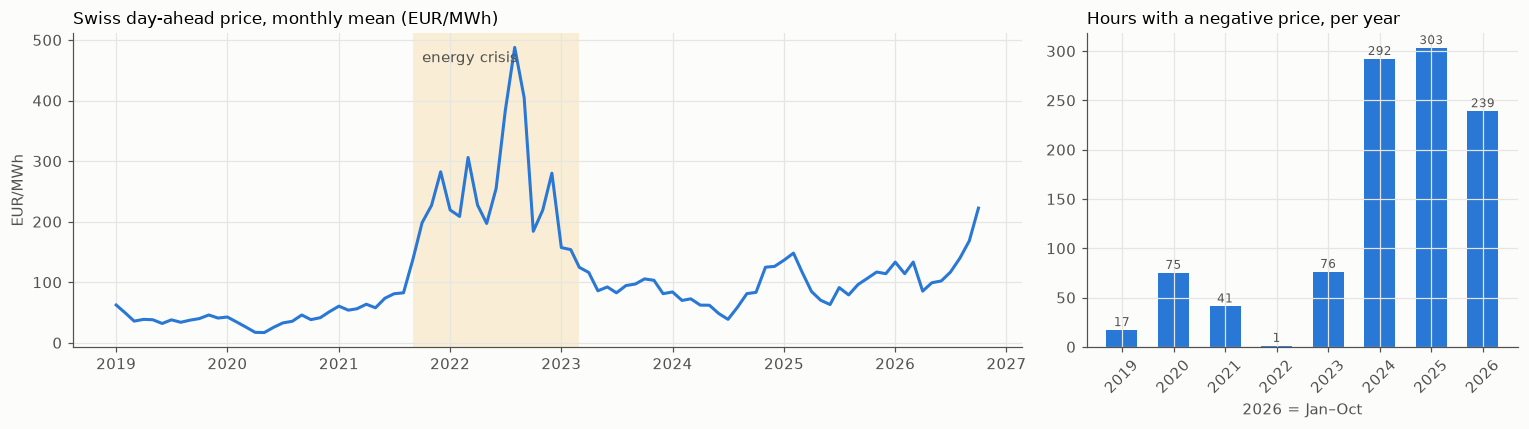

       mean  negative hours
year                       
2019   40.9              17
2020   34.0              75
2021  114.9              41
2022  281.7               1
2023  107.5              76
2024   76.0             292
2025  101.7             303
2026  131.7             239


In [4]:
mon = h.set_index('date').price_eur_mwh.resample('MS').mean()
neg = h.assign(year=h.date.dt.year).groupby('year').price_eur_mwh.apply(lambda s: int((s < 0).sum()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].axvspan(pd.Timestamp('2021-09-01'), pd.Timestamp('2023-03-01'), color=YELLOW, alpha=0.15, lw=0)
ax[0].text(pd.Timestamp('2021-10-01'), mon.max() * 0.95, 'energy crisis', color=INK2)
ax[0].plot(mon.index, mon.values, color=BLUE, lw=2)
ax[0].set_title('Swiss day-ahead price, monthly mean (EUR/MWh)'); ax[0].set_ylabel('EUR/MWh')
ax[1].bar(neg.index.astype(str), neg.values, color=BLUE, width=0.6)
for x_, v in zip(neg.index.astype(str), neg.values): ax[1].text(x_, v + 4, str(v), ha='center', fontsize=8, color=INK2)
ax[1].set_title('Hours with a negative price, per year'); ax[1].set_xlabel('2026 = Jan–Oct')
ax[1].tick_params(axis='x', rotation=45)
fig.tight_layout(); fig.savefig(FIG / 'eda_price_history.png'); plt.show()
print(pd.DataFrame({'mean': h.assign(year=h.date.dt.year).groupby('year').price_eur_mwh.mean().round(1), 'negative hours': neg}).to_string())

The 2021–2022 gas crisis multiplied prices by up to eight; a model that learns the price *level* fails on it,
which is why the price model learns the *change* from today's known price. Negative hours were rare before 2024
and are now a few hundred per year (solar at midday on sunny weekends). October 2026 had none.

## 4. Price shape by block and month (what the battery lives on)

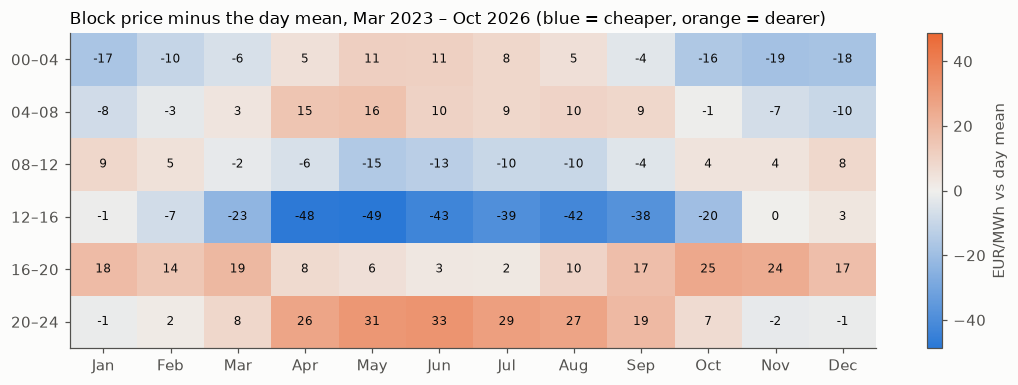

In [5]:
x = h[h.date >= '2023-03-01'].copy()
x['dev'] = x.price_eur_mwh - x.groupby('date').price_eur_mwh.transform('mean')
x['month'] = x.date.dt.month
tab = x.groupby(['block', 'month']).dev.mean().unstack()
cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f0efec', ORANGE])
lim = np.abs(tab.values).max()
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(tab.values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
ax.set_yticks(range(6)); ax.set_yticklabels(['00–04', '04–08', '08–12', '12–16', '16–20', '20–24'])
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
for i in range(6):
    for j in range(12): ax.text(j, i, f'{tab.values[i, j]:.0f}', ha='center', va='center', fontsize=8, color=INK)
ax.grid(False); fig.colorbar(im, ax=ax, label='EUR/MWh vs day mean')
ax.set_title('Block price minus the day mean, Mar 2023 – Oct 2026 (blue = cheaper, orange = dearer)')
fig.tight_layout(); fig.savefig(FIG / 'eda_price_block_month.png'); plt.show()

The battery earns money from the gap between cheap and dear hours of the same day. In spring and summer the
midday block (12–16) is far below the day mean (solar) and the evening block is far above it, so the gap is large.
In winter the shape is flatter, so a battery earns less. Inside a block the spread is even larger: a 2-hour
battery fits inside one 4-hour block, which is why the final plan works with an hourly price shape.

## 5. Missing data

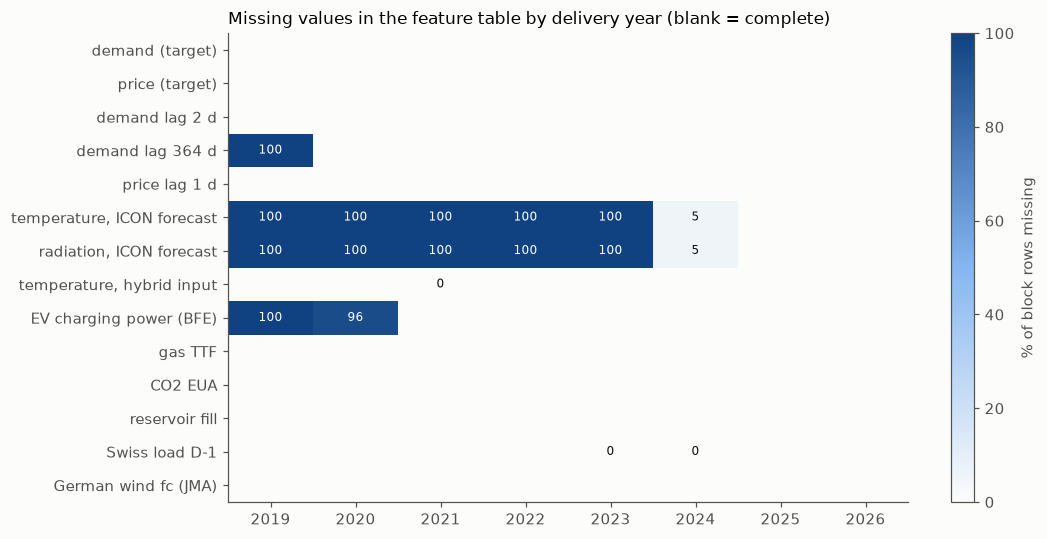

year,2019,2020,2021,2022,2023,2024,2025,2026
demand (target),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
price (target),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
demand lag 2 d,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
demand lag 364 d,99.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0
price lag 1 d,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"temperature, ICON forecast",100.0,100.0,100.0,100.0,100.0,5.3,0.0,0.0
"radiation, ICON forecast",100.0,100.0,100.0,100.0,100.0,5.3,0.0,0.0
"temperature, hybrid input",0.0,0.0,0.4,0.0,0.0,0.0,0.0,0.0
EV charging power (BFE),100.0,95.6,0.0,0.0,0.0,0.0,0.0,0.0
gas TTF,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
f = pd.read_parquet('data/processed/features.parquet')
cols = {'demand (target)': 'demand_mw', 'price (target)': 'price_eur_mwh', 'demand lag 2 d': 'demand_lag_2d_same_block',
        'demand lag 364 d': 'demand_lag_364d_same_block', 'price lag 1 d': 'price_lag_1d_same_block',
        'temperature, ICON forecast': 'temp_c_fc', 'radiation, ICON forecast': 'radiation_wm2_fc',
        'temperature, hybrid input': 'temp_c', 'EV charging power (BFE)': 'charging_kw_zh',
        'gas TTF': 'gas_ttf_d_1', 'CO2 EUA': 'co2_eua_d_1', 'reservoir fill': 'reservoir_fill_pct',
        'Swiss load D-1': 'swiss_load_lag_2d_same_block', 'German wind fc (JMA)': 'eu_wind_cubed_de_mean_jma_safe'}
cols = {k: v for k, v in cols.items() if v in f.columns}
f['year'] = pd.to_datetime(f.delivery_date).dt.year
miss = f.groupby('year')[list(cols.values())].apply(lambda d: d.isna().mean() * 100).T
miss.index = list(cols.keys())
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(miss.values, cmap=LinearSegmentedColormap.from_list('seq', ['#fcfcfb', '#86b6ef', '#104281']), vmin=0, vmax=100, aspect='auto')
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index); ax.set_xticks(range(miss.shape[1])); ax.set_xticklabels(miss.columns)
for i in range(miss.shape[0]):
    for j in range(miss.shape[1]):
        v = miss.values[i, j]
        if v > 0: ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 50 else INK)
ax.grid(False); fig.colorbar(im, ax=ax, label='% of block rows missing')
ax.set_title('Missing values in the feature table by delivery year (blank = complete)')
fig.tight_layout(); fig.savefig(FIG / 'eda_missing_data.png'); plt.show()
miss.round(1)

The targets and the main lags are complete. The gaps are expected and documented: real ICON weather forecasts
only exist from 21 Jan 2024 (before that the hybrid input uses observed weather, a known limitation), the BFE
charging data starts in December 2020, the 364-day lag needs one year of history, and the Swiss load has a few
flagged bad days. Models handle the NaN values (LightGBM natively; ridge with a fill value plus a flag).

## 6. Weather forecast vs observed weather

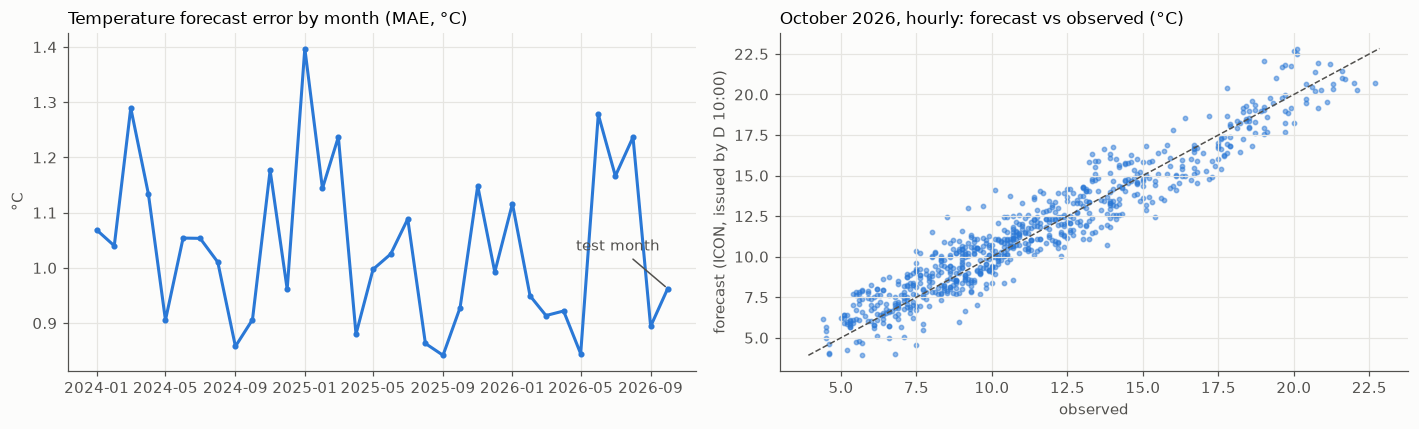

October 2026 temperature MAE (°C): 0.96  radiation MAE (W/m²): 31.5
2024-01-20 → 2026-10 temperature MAE (°C): 1.04


In [7]:
fc = pd.read_parquet('data/processed/weather_forecast_hourly.parquet', columns=['timestamp_utc', 'temp_c_fc_safe_corr', 'radiation_wm2_fc_safe'])
wx = fc.merge(obs, on='timestamp_utc').dropna()
wx = wx[wx.timestamp_utc < '2026-11-01']
wx['err_t'] = wx.temp_c_fc_safe_corr - wx.temp_c
wx['err_r'] = wx.radiation_wm2_fc_safe - wx.radiation_wm2
mm = wx.set_index('timestamp_utc').resample('MS')[['err_t', 'err_r']].apply(lambda d: d.abs().mean())
octo = wx[(wx.timestamp_utc >= '2026-10-01') & (wx.timestamp_utc < '2026-11-01')]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mm.index, mm.err_t, color=BLUE, lw=2, marker='o', ms=3)
ax[0].set_title('Temperature forecast error by month (MAE, °C)'); ax[0].set_ylabel('°C')
ax[0].annotate('test month', (mm.index[-1], mm.err_t.iloc[-1]), xytext=(-60, 25), textcoords='offset points',
               arrowprops=dict(arrowstyle='-', color=INK2), color=INK2)
ax[1].scatter(octo.temp_c, octo.temp_c_fc_safe_corr, s=8, color=BLUE, alpha=0.5)
lo, hi = octo[['temp_c', 'temp_c_fc_safe_corr']].min().min(), octo[['temp_c', 'temp_c_fc_safe_corr']].max().max()
ax[1].plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--')
ax[1].set_title('October 2026, hourly: forecast vs observed (°C)'); ax[1].set_xlabel('observed'); ax[1].set_ylabel('forecast (ICON, issued by D 10:00)')
fig.tight_layout(); fig.savefig(FIG / 'eda_weather_forecast_vs_observed.png'); plt.show()
print('October 2026 temperature MAE (°C):', round(octo.err_t.abs().mean(), 2), ' radiation MAE (W/m²):', round(octo.err_r.abs().mean(), 1))
print('2024-01-20 → 2026-10 temperature MAE (°C):', round(wx.err_t.abs().mean(), 2))

The forecast that was really available at 10:00 on day D misses the observed temperature by about one degree
per hour. In training before 2024 the model saw observed weather instead (no archive of forecasts), so it may
trust the weather a little too much; validation and test use real forecasts only.

**Summary for modelling:** both targets are complete and correctly timed; the main signals are last known demand
and price, calendar and weather; prices have regime changes (crisis, solar build-out), so learning the change from
a known reference is safer than learning the level.